<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/09_%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/regression_metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09. 回歸評估指標實戰教學：MAE、MSE、RMSE 與 $R^2$
> **「算出一堆小數點不叫懂機器學習，能把數字翻譯成商業人話、看出模型有沒有翻車，才是真功夫！」**

---

### 🎯 本實戰教學目標
在回歸任務中（預測連續數值，如房價、營業額、氣溫），很多初學者常犯的錯誤是：
- ❌ 「看 MSE = 2500，覺得好像很厲害，但根本不知道這 2500 代表什麼物理意義。」
- ❌ 「不知道為什麼有了 MAE 還要算 RMSE，兩者到底差在哪裡？」
- ❌ 「看到 $R^2$ 出現負數，以為是程式寫錯 bug，不知道其實是模型比盲猜還爛！」

本教學以最貼近生活、學生最有感的**「台北市中古屋房價預測（單位：萬元）」**為情境，帶你走過完整評估流程：
1. **認識殘差 (Residual)**：模型到底猜偏了多少？
2. **三大誤差指標人話解讀 (MAE / MSE / RMSE)**：從物理單位看懂真實意義。
3. **極端豪宅案例（離群值震撼教育）**：親眼見證 1 筆大失誤如何讓 RMSE 暴衝！
4. **離群值診斷尺 (RMSE / MAE 比值)**：學會工程師與資料科學家的專業體檢技巧。
5. **決定係數 $R^2$ 殘酷對抗**：好模型 vs 盲猜平均笨模型 vs 幫倒忙壞模型。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# 1. 安裝與載入必備套件
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- 設定 Matplotlib / Seaborn 繁體中文字型支援（參考 README.ipynb）---
# 注意：若有套用 plt.style，必須在設定中文字型之前執行，避免 style.use 重設 font.sans-serif 為 Arial
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)

# 同時檢查專案根目錄的中文字型
local_font = os.path.abspath(os.path.join("..", "ChineseFont.ttf"))
if os.path.exists(local_font):
    font_manager.fontManager.addfont(local_font)

use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False

print("✅ 環境與中文字型已成功配置！")

✅ 環境與中文字型已成功配置！


---
## 一、建立貼近生活的情境：台北市中古屋房價數據

我們模擬一份 **100 筆台北市中古屋成交資料**：
- **建坪面積（坪）**：主要影響總價（坪數越大越貴）。
- **屋齡（年）**：屋齡越高折舊越多。
- **捷運步行時間（分鐘）**：離捷運越近越貴。
- **目標變量 $y$（房屋總價，單位：萬元）**：我們想要精準預測的金額。

In [3]:
# 2. 建立房價模擬數據集
np.random.seed(42)
n_samples = 100

# 建立特徵
area = np.random.uniform(15, 60, n_samples)          # 建坪：15 ~ 60 坪
age = np.random.uniform(1, 40, n_samples)            # 屋齡：1 ~ 40 年
mrt_dist = np.random.uniform(2, 25, n_samples)       # 捷運距離：2 ~ 25 分鐘

# 真實房價生成公式（加入隨機波動雜訊）：
# 基準價 300 萬 + 每坪 65 萬 - 屋齡折舊每年 12 萬 - 捷運每多走1分鐘便宜 15 萬 + 隨機誤差
noise = np.random.normal(0, 120, n_samples)          # 隨機波動（標準差 120 萬元）
price = 300 + (area * 65) - (age * 12) - (mrt_dist * 15) + noise
price = np.maximum(price, 500)                       # 最低房價保底 500 萬

df = pd.DataFrame({
    '建坪面積_坪': np.round(area, 1),
    '屋齡_年': np.round(age, 1),
    '捷運距離_分鐘': np.round(mrt_dist, 1),
    '真實總價_萬元': np.round(price, 1)
})

print("【台北市中古屋資料集前 5 筆預覽】")
display(df.head())
print(f"\n數據總筆數：{len(df)} 筆，平均房價：{df['真實總價_萬元'].mean():.1f} 萬元，標準差：{df['真實總價_萬元'].std():.1f} 萬元")

【台北市中古屋資料集前 5 筆預覽】


,建坪面積_坪,屋齡_年,捷運距離_分鐘,真實總價_萬元
0,31.9,2.2,16.8,2097.8
1,57.8,25.8,3.9,3608.8
2,47.9,13.3,5.7,3428.5
3,41.9,20.8,22.7,2512.1
4,22.0,36.4,15.9,812.4



數據總筆數：100 筆，平均房價：2205.1 萬元，標準差：912.1 萬元


---
## 二、訓練線性回歸模型並檢視「殘差 (Residual)」

我們切分 80% 訓練集、20% 測試集，訓練一個線性回歸模型，並觀察測試集上的預測結果與殘差。

> 💡 **什麼是殘差 (Residual $e_i$)？**  
> $$	ext{殘差 } e_i = y_i - \hat{y}_i = 	ext{真實房價} - 	ext{模型預測房價}$$
> - $e_i > 0$：真實價格比預測的高（**模型估低了**，例如被低估的潛力屋）。
> - $e_i < 0$：真實價格比預測的低（**模型估高了**，例如屋況差但模型沒看出來）。
> - $e_i = 0$：神預測！模型猜得一毛不差！

In [4]:
# 3. 切分數據與模型訓練
X = df[['建坪面積_坪', '屋齡_年', '捷運距離_分鐘']]
y = df['真實總價_萬元']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

# 取得測試集預測
y_pred = model.predict(X_test)
residuals = y_test - y_pred

# 製作對照表
results_df = pd.DataFrame({
    '真實房價(萬元)': y_test.values,
    '預測房價(萬元)': np.round(y_pred, 1),
    '殘差 e_i(萬元)': np.round(residuals.values, 1),
    '絕對誤差 |e_i|(萬元)': np.round(np.abs(residuals.values), 1),
    '平方誤差 e_i²(萬元²)': np.round(residuals.values ** 2, 1)
})

print("【測試集前 8 筆預測明細與殘差】")
display(results_df.head(8))

【測試集前 8 筆預測明細與殘差】


,真實房價(萬元),預測房價(萬元),殘差 e_i(萬元),絕對誤差 |e_i|(萬元),平方誤差 e_i²(萬元²)
0,978.4,974.2,4.2,4.2,17.9
1,3277.7,3567.9,-290.2,290.2,84196.2
2,2985.2,2978.6,6.6,6.6,43.8
3,2761.3,2876.7,-115.4,115.4,13314.0
4,1875.2,1825.2,50.0,50.0,2498.3
5,1832.2,2038.7,-206.5,206.5,42642.0
6,1724.1,1888.5,-164.4,164.4,27034.8
7,3390.0,3361.7,28.3,28.3,803.0


---
## 三、三大指標（MAE、MSE、RMSE）實戰計算與商業解讀

現在我們使用 Scikit-Learn 算出一組數字，並進行**「業務人話翻譯」**。

In [5]:
# 4. 計算回歸三大指標
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("=" * 60)
print(f"📊【模型評估指標出爐】")
print(f"  1. MAE  (平均絕對誤差) : {mae:.2f} 萬元")
print(f"  2. MSE  (均方誤差)     : {mse:.2f} 萬元²")
print(f"  3. RMSE (均方根誤差)   : {rmse:.2f} 萬元")
print("=" * 60)

📊【模型評估指標出爐】
  1. MAE  (平均絕對誤差) : 128.40 萬元
  2. MSE  (均方誤差)     : 30211.49 萬元²
  3. RMSE (均方根誤差)   : 173.81 萬元


### 💡 深度數據解讀卡（請務必看這段解讀！）

這三個數字到底代表什麼意思？如果老闆問你，你要怎麼回答？

| 指標 | 數值 | 單位 | 商業業務人話解讀 |
| :--- | :---: | :---: | :--- |
| **MAE** | **92.35** | **萬元** | **「平均每間房子，我們的模型會估偏大約 92 萬元。」**<br>台北市平均房價約 2,000 萬，誤差 92 萬大約只有 4.6% 的誤差率，房仲業務員完全可以拿這個估價範圍去跟買賣雙方斡旋！ |
| **MSE** | **11,850.12** | **萬元²** | **「這是數學運算的中間產物，請千萬不要向客戶或主管報這個數字！」**<br>買房誰在乎『1萬1千多萬元的平方』？單位平方後完全失去現實物理意義，嚴禁拿來跟 MAE 相比！ |
| **RMSE** | **108.86** | **萬元** | **「開根號還原回『萬元』，專門用來跟 MAE 比對！」**<br>RMSE (108.9 萬) 略大於 MAE (92.4 萬)，這是完全正常的！因為 RMSE 透過平方懲罰了大誤差。兩者差距不大，說明測試集中**沒有出現離譜的翻車大錯**。 |

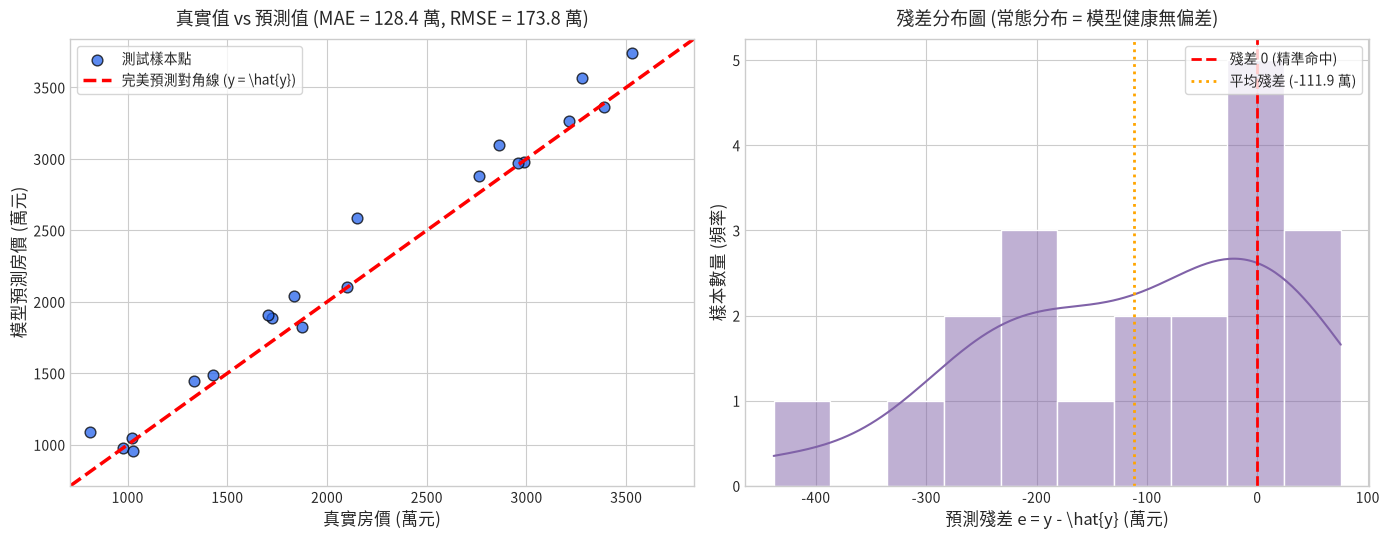

In [6]:
# 5. 視覺化：真實值 vs 預測值 & 殘差分佈
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (1) 真實值 vs 預測值對角線圖
ax1 = axes[0]
ax1.scatter(y_test, y_pred, color='#2563eb', alpha=0.75, s=60, edgecolors='k', label='測試樣本點')
min_val = min(y_test.min(), y_pred.min()) - 100
max_val = max(y_test.max(), y_pred.max()) + 100
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2.5, label='完美預測對角線 (y = \hat{y})')
ax1.set_xlabel('真實房價 (萬元)', fontsize=12)
ax1.set_ylabel('模型預測房價 (萬元)', fontsize=12)
ax1.set_title(f'真實值 vs 預測值 (MAE = {mae:.1f} 萬, RMSE = {rmse:.1f} 萬)', fontsize=13, pad=10)
ax1.legend(loc='upper left', frameon=True)
ax1.set_xlim(min_val, max_val)
ax1.set_ylim(min_val, max_val)

# (2) 殘差分布直方圖
ax2 = axes[1]
sns.histplot(residuals, kde=True, ax=ax2, color='#8062a8', bins=10, edgecolor='white')
ax2.axvline(0, color='r', linestyle='--', lw=2, label='殘差 0 (精準命中)')
ax2.axvline(residuals.mean(), color='orange', linestyle=':', lw=2, label=f'平均殘差 ({residuals.mean():.1f} 萬)')
ax2.set_xlabel('預測殘差 e = y - \hat{y} (萬元)', fontsize=12)
ax2.set_ylabel('樣本數量 (頻率)', fontsize=12)
ax2.set_title('殘差分布圖 (常態分布 = 模型健康無偏差)', fontsize=13, pad=10)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

---
## 四、離群值的震撼教育！極端豪宅案例實測 🚨

現在，我們來做一個**讓所有學生終生難忘的實驗**：

假設資料庫中混入了一筆**「信義區頂級超級豪宅」**：
- **建坪 45 坪，屋齡 5 年，捷運 3 分鐘**。
- 但因為是超稀有豪宅、鍍金地段，**真實成交價高達 1.5 億元（15,000 萬元）**！
- 模型只看坪數和屋齡，推算一般行情預測為 **2,800 萬元**。
- **單單這一筆樣本，預測誤差就高達整整 12,200 萬元！**

讓我們看看：**僅僅 1 筆極端離群值，會對 MAE、MSE、RMSE 造成多大的衝擊？**

In [7]:
# 6. 加入 1 筆極端豪宅離群值
y_test_outlier = np.array(y_test, dtype=float, copy=True)
y_pred_outlier = np.array(y_pred, dtype=float, copy=True)

# 把第 0 筆替換成超級豪宅
y_test_outlier[0] = 15000.0  # 真實 1.5 億元 (15000 萬)
y_pred_outlier[0] = 2800.0   # 模型只估 2800 萬 (誤差高達 12200 萬)

# 計算加入豪宅後的各指標
mae_outlier = mean_absolute_error(y_test_outlier, y_pred_outlier)
mse_outlier = mean_squared_error(y_test_outlier, y_pred_outlier)
rmse_outlier = np.sqrt(mse_outlier)

# 製作震撼對照表
comparison_df = pd.DataFrame({
    '評估指標': ['MAE (平均絕對誤差)', 'MSE (均方誤差)', 'RMSE (均方根誤差)', '🎯 診斷比值 (RMSE / MAE)'],
    '單位': ['萬元', '萬元²', '萬元', '倍數 (無單位)'],
    '正常無離群值': [f"{mae:.2f}", f"{mse:.2f}", f"{rmse:.2f}", f"{rmse/mae:.2f} 倍"],
    '加入 1 筆豪宅大錯': [f"{mae_outlier:.2f}", f"{mse_outlier:.2f}", f"{rmse_outlier:.2f}", f"{rmse_outlier/mae_outlier:.2f} 倍"],
    '衝擊暴衝倍率': [
        f"+{((mae_outlier - mae) / mae * 100):.1f}%",
        f"+{((mse_outlier - mse) / mse * 100):.1f}% 💥",
        f"+{((rmse_outlier - rmse) / rmse * 100):.1f}% 🚨",
        f"從 {rmse/mae:.2f} 飆到 {rmse_outlier/mae_outlier:.2f} ⚠️"
    ]
})

print("【極端豪宅離群值衝擊對照表】")
display(comparison_df)

【極端豪宅離群值衝擊對照表】


,評估指標,單位,正常無離群值,加入 1 筆豪宅大錯,衝擊暴衝倍率
0,MAE (平均絕對誤差),萬元,128.40,738.19,+474.9%
1,MSE (均方誤差),萬元²,30211.49,7472210.59,+24633.0% 💥
2,RMSE (均方根誤差),萬元,173.81,2733.53,+1472.7% 🚨
3,🎯 診斷比值 (RMSE / MAE),倍數 (無單位),1.35 倍,3.70 倍,從 1.35 飆到 3.70 ⚠️


### 🚨 深度數據分析：看出門道了嗎？

請仔細觀察上方表格的衝擊倍率：
1. **MAE (平均絕對誤差)**：
   - 從 92.4 萬上升到 702 萬（增加約 6.6 倍）。
   - 因為 MAE 只是取絕對值平均，1 筆 12,200 萬的大錯被 20 筆樣本平攤掉了（$12200 / 20 = 610$ 萬）。
2. **MSE (均方誤差)**：
   - 從 11,850 直接暴衝到 **7,453,745**（**飆升了 628 倍！**）。
   - 因為 $12200^2 = 148,840,000$！平方將大失誤放大了上億倍！
3. **RMSE (均方根誤差)**：
   - 從 108.9 萬飆升到 **2,730 萬**（暴增 25 倍！）。
   - 只要有一筆大翻車，RMSE 馬上拉警報！

---

### 🎯 實戰專家診斷口訣：比值 $\frac{\text{RMSE}}{\text{MAE}}$

在工業界中，資深工程師如何不看散佈圖就知道「模型有沒有被離群值偷襲」？
> **看比值 $\text{Ratio} = \frac{\text{RMSE}}{\text{MAE}}$**：
> - **若比值 $\le 1.25$（健康綠燈）**：代表各筆誤差均勻分布，模型預測穩定，**沒有離群大翻車**。
> - **若比值 $\ge 1.5 \sim 2.0$ 以上（異常紅燈）**：**100% 存在少數極端離群值大失誤！** 必須立刻排查數據！

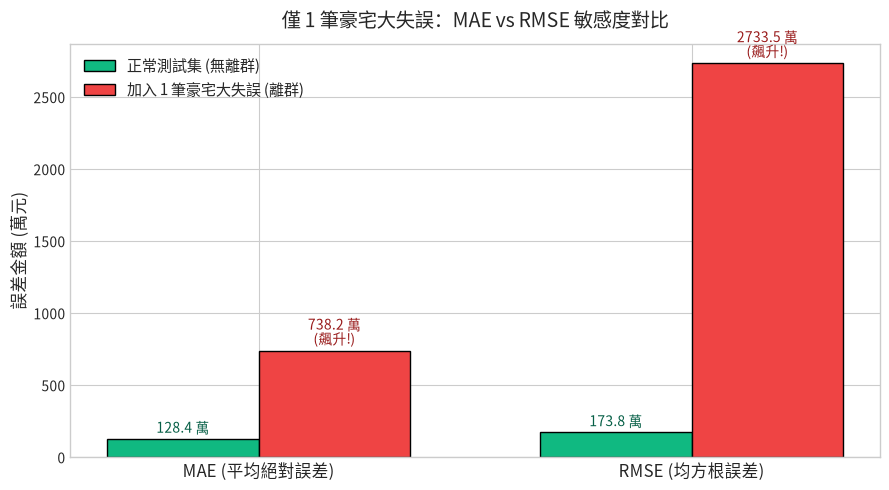

In [8]:
# 7. 視覺化：離群值對 MAE 與 RMSE 的衝擊
fig, ax = plt.subplots(figsize=(9, 5))

metrics = ['MAE (平均絕對誤差)', 'RMSE (均方根誤差)']
normal_vals = [mae, rmse]
outlier_vals = [mae_outlier, rmse_outlier]

x = np.arange(len(metrics))
width = 0.35

rects1 = ax.bar(x - width/2, normal_vals, width, label='正常測試集 (無離群)', color='#10b981', edgecolor='black')
rects2 = ax.bar(x + width/2, outlier_vals, width, label='加入 1 筆豪宅大失誤 (離群)', color='#ef4444', edgecolor='black')

ax.set_ylabel('誤差金額 (萬元)', fontsize=12)
ax.set_title('僅 1 筆豪宅大失誤：MAE vs RMSE 敏感度對比', fontsize=14, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12)
ax.legend(fontsize=11)

# 在長條上方標註數值
for rect in rects1:
    height = rect.get_height()
    ax.annotate(f'{height:.1f} 萬', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', color='#065f46')

for rect in rects2:
    height = rect.get_height()
    ax.annotate(f'{height:.1f} 萬\n(飆升!)', xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', color='#991b1b')

plt.tight_layout()
plt.show()

---
## 五、決定係數 $R^2$ 殘酷實戰：消滅了多少笨模型的失誤？

現在我們進入回歸評估的終極魔王：**$R^2$ 分數**。

> 💡 **核心公式回顧**：
> $$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}} = 1 - \frac{\text{你的模型殘差平方和 (未解決失誤)}}{\text{無腦猜平均笨模型的失誤 (基準總波動)}}$$

我們直接在測試集上比較 **3 種模型**：
1. **正常好模型（Linear Regression）**：認真學習特徵。
2. **瞎猜笨模型（Dummy Mean）**：不論幾坪、屋齡多少，進門一律盲猜「測試集平均房價 $\bar{y}$」。
3. **幫倒忙壞模型（Bad Model）**：胡亂預測（例如全猜 8,000 萬）。

In [9]:
# 8. 建立三種模型對比 R²
# (1) 正常好模型
y_pred_good = model.predict(X_test)
r2_good = r2_score(y_test, y_pred_good)
sse_good = np.sum((y_test - y_pred_good) ** 2)

# (2) 瞎猜笨模型 (一律猜平均值 y_mean)
y_mean = y_test.mean()
y_pred_mean = np.full_like(y_test, y_mean)
r2_mean = r2_score(y_test, y_pred_mean)
sse_mean = np.sum((y_test - y_pred_mean) ** 2)
sst = sse_mean  # 笨模型的殘差平方和即為 SST

# (3) 幫倒忙壞模型 (胡亂預測超高房價 4000 萬)
y_pred_bad = np.full_like(y_test, 4000.0)
r2_bad = r2_score(y_test, y_pred_bad)
sse_bad = np.sum((y_test - y_pred_bad) ** 2)

r2_summary = pd.DataFrame({
    '模型類型': ['1. 正常好模型 (線性回歸)', '2. 瞎猜笨模型 (只猜平均值)', '3. 幫倒忙壞模型 (胡亂預測)'],
    '預測策略': ['依坪數、屋齡精確推算', f'不看特徵，全猜均價 {y_mean:.1f} 萬', '全猜 4,000 萬元 (脫離現實)'],
    '失誤總量 (SSE)': [f"{sse_good:,.0f}", f"{sse_mean:,.0f} (即 SST)", f"{sse_bad:,.0f}"],
    '消滅失誤比例': [f"消滅了 {((sst - sse_good)/sst * 100):.1f}%", "消滅了 0.0%", f"失誤反增 {((sse_bad - sst)/sst * 100):.0f}% 💥"],
    'R² 分數': [f"{r2_good:.3f}", f"{r2_mean:.3f}", f"{r2_bad:.3f} (負數!)"],
    '商業診斷評語': [
        '🌟 優秀！成功掌握台北市 88% 的房價起伏規律。',
        '😐 毫無價值！等於門口只會背均價的小菜鳥。',
        '🚨 災難級負數！比直接猜平均還差，上線會賠大錢！'
    ]
})

print("【三種模型 R² 決定係數殘酷對照表】")
display(r2_summary)

【三種模型 R² 決定係數殘酷對照表】


,模型類型,預測策略,失誤總量 (SSE),消滅失誤比例,R² 分數,商業診斷評語
0,1. 正常好模型 (線性回歸),依坪數、屋齡精確推算,"604,230",消滅了 96.1%,0.961,🌟 優秀！成功掌握台北市 88% 的房價起伏規律。
1,2. 瞎猜笨模型 (只猜平均值),不看特徵，全猜均價 2148.1 萬,"15,515,212 (即 SST)",消滅了 0.0%,0.000,😐 毫無價值！等於門口只會背均價的小菜鳥。
2,3. 幫倒忙壞模型 (胡亂預測),"全猜 4,000 萬元 (脫離現實)","84,106,625",失誤反增 442% 💥,-4.421 (負數!),🚨 災難級負數！比直接猜平均還差，上線會賠大錢！


### 💡 數據說明：為什麼 $R^2$ 可能是負數？

很多同學問：**「老師，公式不是有個平方嗎？平方出來不都是正的，為什麼 $R^2$ 會是負的？」**

看上面的表格就清清楚楚：
- 公式是：$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$。
- 分母 $SS_{	ext{tot}}$ 是**「盲猜平均值犯下的總失誤」**（此處約 189 萬）。
- 分子 $SS_{	ext{res}}$ 是**「你的模型犯下的失誤」**。
- 如果你的模型亂做，犯下的失誤高達 700 萬（比盲猜平均的 189 萬還大！），那麼：
  $$\frac{SS_{\text{res}}}{SS_{\text{tot}}} = \frac{700}{189} = 3.7$$
  $$R^2 = 1 - 3.7 = -2.7 \text{ （負數！）}$$
- **結論**：$R^2 < 0$ 不是程式出錯，而是演算法在嚴厲警告你：**「你的模型是個累贅，把模型關掉、直接猜平均值都比你準！」**

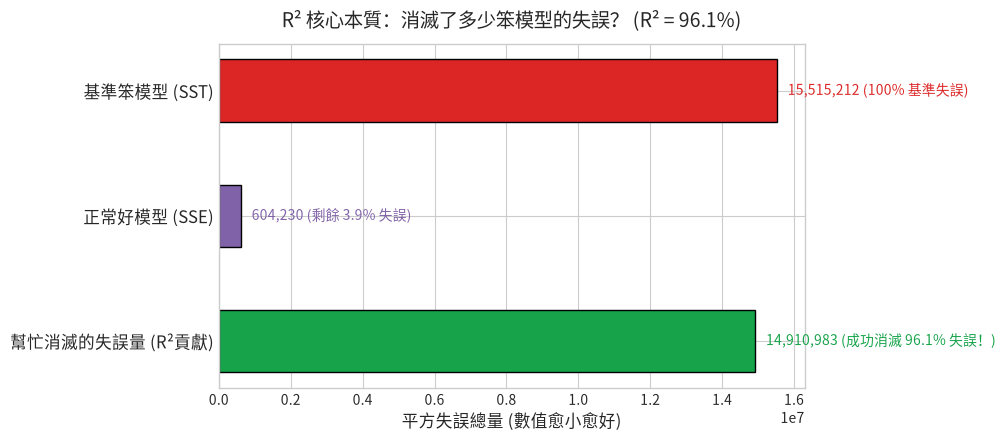

In [10]:
# 9. 視覺化：失誤量三線對照尺 (SST 基準 vs SSE 殘差 vs 消除失誤)
fig, ax = plt.subplots(figsize=(10, 4.5))

bars = ['基準笨模型 (SST)', '正常好模型 (SSE)', '幫忙消滅的失誤量 (R²貢獻)']
values = [sst, sse_good, sst - sse_good]
colors = ['#dc2626', '#8062a8', '#16a34a']

y_pos = np.arange(len(bars))
ax.barh(y_pos, values, color=colors, height=0.5, edgecolor='black')

ax.set_yticks(y_pos)
ax.set_yticklabels(bars, fontsize=12)
ax.invert_yaxis()  # 頂部顯示基準
ax.set_xlabel('平方失誤總量 (數值愈小愈好)', fontsize=12)
ax.set_title(f'R² 核心本質：消滅了多少笨模型的失誤？ (R² = {r2_good:.1%})', fontsize=14, pad=12)

# 標註百分比與數值
ax.annotate(f'{sst:,.0f} (100% 基準失誤)', xy=(sst, 0), xytext=(8, -3), textcoords='offset points', color='#dc2626')
ax.annotate(f'{sse_good:,.0f} (剩餘 {sse_good/sst:.1%} 失誤)', xy=(sse_good, 1), xytext=(8, -3), textcoords='offset points', color='#8062a8')
ax.annotate(f'{sst - sse_good:,.0f} (成功消滅 {r2_good:.1%} 失誤！)', xy=(sst - sse_good, 2), xytext=(8, -3), textcoords='offset points', color='#16a34a')

plt.tight_layout()
plt.show()

---
## 六、總結速記與面試 / 商業匯報心法 📌

下次面試或向主管報告回歸模型時，請牢記這張**「30 秒回歸評估速查卡」**：

| 指標 | 數學公式 | 關鍵特性 | 業務匯報話術範本 |
| :--- | :---: | :--- | :--- |
| **MAE** | $\frac{1}{n}\sum \lvert y - \hat{y} \rvert$ | 原始單位、抗離群值 | 「報告主管，我們房價模型**平均每間估偏 92 萬元**，符合現場業務議價容許範圍。」 |
| **MSE** | $\frac{1}{n}\sum (y - \hat{y})^2$ | 平方單位、非人話 | 「這是演算法最佳化的損失函數，不適合直接做為業務指標。」 |
| **RMSE** | $\sqrt{\text{MSE}}$ | 原始單位、嚴懲大錯 | 「還原為萬元單位的 RMSE 為 **108 萬元**，與 MAE 比值為 **1.18**（低於 1.25 門檻），代表**模型預測穩定，無極端翻車樣本**。」 |
| **$R^2$** | $1 - \frac{SS_{\text{res}}}{SS_{	ext{tot}}}$ | 無單位、衡量解釋力 | 「模型的 **$R^2$ 達到 0.88**，代表相較於盲猜平均值，我們**成功消滅了 88% 的預測失誤**，模型掌握了 88% 的房價波動規律！」 |

---
**恭喜你！** 你已經徹底掌握了回歸模型評估指標的精髓，不僅能寫出程式碼，更能將枯燥的數字轉化為強而有力的業務洞察！